# Importando as bibliotecas

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from googledrivedownloader import download_file_from_google_drive as gdd

# Carregar o conjunto de dados

In [2]:
data_id = "1JO3pUwiQtgDf8UWudWQafRQk29S204c0"
data_pasta = "./dados.csv"
gdd(file_id=data_id, dest_path=data_pasta, showsize=True, overwrite=True)

32.0 KiB Done.


In [3]:
df = pd.read_csv(data_pasta, sep=',')

# Medidas de centralidade

*   Média;
*   Mediana;
*   Moda.





## Já foi tratado esse assunto

# Medidas de dispersão

## Variância

In [4]:
A = [23,24,25,26,27]
B = [21,22,25,28,29]
exemplo = pd.DataFrame(
    {'A' : A,
     'B' : B} # Chaves
    )
exemplo.head()

,A,B
0,23,21
1,24,22
2,25,25
3,26,28
4,27,29


In [5]:
print(f"Média de A: {exemplo['A'].mean()}")
print(f"Média de B: {exemplo['B'].mean()}")

Média de A: 25.0
Média de B: 25.0


In [6]:
A = [23,24,25,26,27]
B = [21,22,25,28,29]
dA = []
dB = []
mediaA = sum(A)/len(A)
mediaB = sum(B)/len(B)
for (idadeA,idadeB) in zip(A,B):
  dist_A = idadeA - mediaA
  dist_B = idadeB - mediaB
  dA.append(dist_A**2)
  dB.append(dist_B**2)
print(sum(dA)/(len(dA)-1))
print(sum(dB)/(len(dB)-1))

2.5
12.5


In [7]:
exemplo["A"].var()

2.5

In [8]:
exemplo["B"].var()

12.5

In [9]:
exemplo["A"].std()

1.5811388300841898

In [10]:
exemplo["B"].std()

3.5355339059327378

## Amplitude dos dados

In [11]:
minimo = exemplo["B"].min()
maximo = exemplo["B"].max()
amplitude = maximo - minimo
print(f"A amplitude dos dados é: {amplitude}")

A amplitude dos dados é: 8


In [12]:
# Exercício:
# Para conjunto de dados da aula (df), verifique calcule á média, var e desvio padrão de RestingBP para pessoas que tem problemas cardiácos (HeartDisease->1) e quem não tem problema cardiáco (HeartDisease->0)
mask_sem_pc = df['HeartDisease'] == 0
mask_com_pc = df['HeartDisease'] == 1
print("Sem problema cardiáco:")
print(f"A média é {df[mask_sem_pc]['RestingBP'].mean()}")
print(f"A variância é {df[mask_sem_pc]['RestingBP'].var()}")
print(f"O desvio padrão é {df[mask_sem_pc]['RestingBP'].std()}")
print("Com problema cardiáco:")
print(f"A média é {df[mask_com_pc]['RestingBP'].mean()}")
print(f"A variância é {df[mask_com_pc]['RestingBP'].var()}")
print(f"O desvio padrão é {df[mask_com_pc]['RestingBP'].std()}")

Sem problema cardiáco:
A média é 130.18048780487806
A variância é 272.23629315999835
O desvio padrão é 16.49958463598397
Com problema cardiáco:
A média é 134.18503937007873
A variância é 393.1767382627472
O desvio padrão é 19.828684733555757


In [13]:
# Avaliando a diferença entre média e mediana
dados = pd.DataFrame({
    "Temperatura":[70,71,75,72,73,69,71,72,150]
    })
print(f"Média: {dados['Temperatura'].mean()}")
print(f"Mediana: {dados['Temperatura'].median()}")

Média: 80.33333333333333
Mediana: 72.0


# Analisando os valores discrepantes (outliers) com o boxplot

In [14]:
idades = [18,20,22,24,26,28,30,32,34,50]
ex_2 = pd.DataFrame({
    "idade" : idades
})
ex_2.head()

,idade
0,18
1,20
2,22
3,24
4,26


In [15]:
import numpy as np
np.quantile(ex_2['idade'], [0.25,0.5,0.75])

array([22.5, 27. , 31.5])

## Limites superiores e inferiores do boxplot

### Distância interquartil (IQR)

$IQR = Q_3 - Q_1$

In [16]:
(q1,q2,q3) = np.quantile(ex_2['idade'], [0.25,0.5,0.75])
iqr = q3 - q1
print(f"A distância interquartil é: {iqr}")

A distância interquartil é: 9.0


## Limite inferior e superior de boxplot

$LI =  Q_1 - IQR \times 1,5$

In [17]:
li = q1 - iqr*1.5
print(f"O limite inferior é: {li}")

O limite inferior é: 9.0


$LS = Q_3 + IQR \times 1,5$

In [18]:
li = q3 + iqr*1.5
print(f"O limite superior é: {li}")

O limite superior é: 45.0


## Criando gráfico do boxplot com o seaborn

Text(0.5, 0, 'Idades')

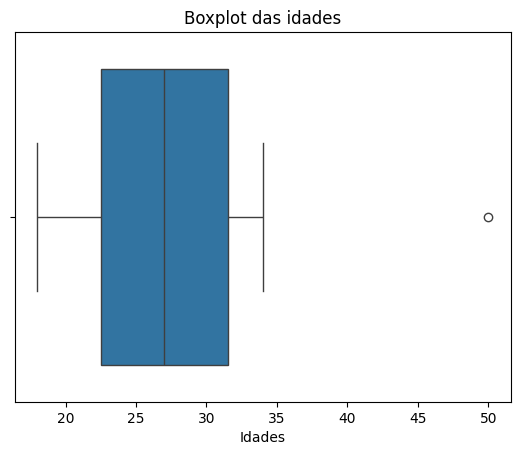

In [21]:
sns.boxplot(data=ex_2, x="idade")
plt.title("Boxplot das idades")
plt.xlabel("Idades")

<Axes: xlabel='MaxHR'>

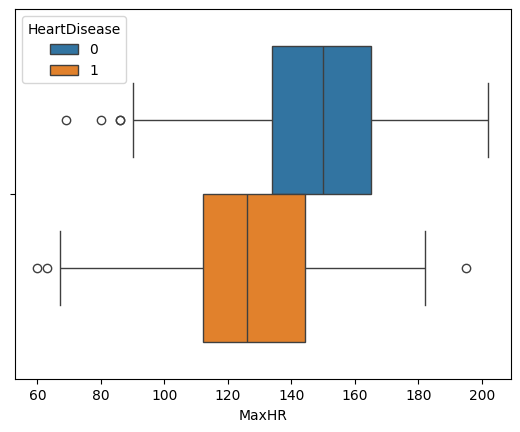

In [24]:
sns.boxplot(data=df, x="MaxHR", hue="HeartDisease")